# Air Quality Index (AQI) Prediction using Random Forest Regressor

**Objective:** Predict the **next day's AQI** of an air-quality monitoring station from today's pollutant concentrations.

**Dataset:** `station_day.csv` — daily pollutant readings from monitoring stations across Indian cities (PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene, AQI, AQI_Bucket).

**ML Pipeline followed in this notebook:**
1. Import libraries
2. Load the dataset
3. Understand the data
4. Handling missing values (imputation)
5. Data preprocessing & target creation
6. Feature selection
7. Train–test split
8. Model building – Random Forest Regressor
9. Prediction
10. Model evaluation
11. Feature importance
12. Saving the model (Serialization)
13. Loading the model & predicting on new data (Reusability)
14. Conclusion

## Step 1: Import Libraries
- **pandas / numpy** – data handling
- **matplotlib / seaborn** – visualisation
- **scikit-learn** – splitting, imputation, model and metrics
- **joblib** – saving / loading the trained model

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

c:\Users\Kumar\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## Step 2: Load the Dataset
The CSV file is read into a pandas DataFrame. Each row is one station's readings for one day.

In [2]:
df = pd.read_csv('station_day.csv')
df.head()

,StationId,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,AP001,24-11-2017,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92,0.10,NaN,NaN
1,AP001,25-11-2017,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50,0.06,184.0,Moderate
2,AP001,26-11-2017,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95,0.08,197.0,Moderate
3,AP001,27-11-2017,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63,0.12,198.0,Moderate
4,AP001,28-11-2017,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02,0.07,188.0,Moderate


## Step 3: Understand the Data
### 3.1 Shape of the dataset

In [3]:
print('Rows    :', df.shape[0])
print('Columns :', df.shape[1])

Rows    : 108035
Columns : 16


### 3.2 Column names, data types and non-null counts

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 108035 entries, 0 to 108034
Data columns (total 16 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   StationId   108035 non-null  str    
 1   Date        108035 non-null  str    
 2   PM2.5       86410 non-null   float64
 3   PM10        65329 non-null   float64
 4   NO          90929 non-null   float64
 5   NO2         91488 non-null   float64
 6   NOx         92535 non-null   float64
 7   NH3         59930 non-null   float64
 8   CO          95037 non-null   float64
 9   SO2         82831 non-null   float64
 10  O3          82467 non-null   float64
 11  Benzene     76580 non-null   float64
 12  Toluene     69333 non-null   float64
 13  Xylene      22898 non-null   float64
 14  AQI         87025 non-null   float64
 15  AQI_Bucket  87025 non-null   str    
dtypes: float64(13), str(3)
memory usage: 15.4 MB


### 3.3 Statistical summary of numerical columns

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PM2.5,86410.0,80.272571,76.526403,0.02,31.880,55.95,99.9200,1000.00
PM10,65329.0,157.968427,123.418672,0.01,70.150,122.09,208.6700,1000.00
NO,90929.0,23.123424,34.491019,0.01,4.840,10.29,24.9800,470.00
NO2,91488.0,35.240760,29.510827,0.01,15.090,27.21,46.9300,448.05
NOx,92535.0,41.195055,45.145976,0.00,13.970,26.66,50.5000,467.63
NH3,59930.0,28.732875,24.897797,0.01,11.900,23.59,38.1375,418.90
CO,95037.0,1.605749,4.369578,0.00,0.530,0.91,1.4500,175.81
SO2,82831.0,12.257634,12.984723,0.01,5.040,8.95,14.9200,195.65
O3,82467.0,38.134836,39.128004,0.01,18.895,30.84,47.1400,963.00
Benzene,76580.0,3.358029,11.156234,0.00,0.160,1.21,3.6100,455.03


### 3.4 Missing values in each column
Air-quality sensors often fail or skip readings, so missing values are expected.

In [6]:
missing = df.isnull().sum().to_frame('Missing Count')
missing['Missing %'] = (missing['Missing Count'] / len(df) * 100).round(2)
missing.sort_values('Missing %', ascending=False)

,Missing Count,Missing %
Xylene,85137,78.81
NH3,48105,44.53
PM10,42706,39.53
Toluene,38702,35.82
Benzene,31455,29.12
O3,25568,23.67
SO2,25204,23.33
PM2.5,21625,20.02
AQI_Bucket,21010,19.45
AQI,21010,19.45


### 3.5 Number of unique stations

In [7]:
print('Number of stations:', df['StationId'].nunique())

Number of stations: 110


## Step 4: Handling Missing Values (Imputation)
Missing pollutant readings are filled with the **median** of each column using `SimpleImputer`.
- Median is used because pollutant data is skewed and has outliers.
- Only the 12 pollutant columns are imputed. `AQI` is **not** imputed, because it is used to build the target.

In [8]:
features = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']

print('Missing values before imputation:')
print(df[features].isnull().sum())

Missing values before imputation:
PM2.5      21625
PM10       42706
NO         17106
NO2        16547
NOx        15500
NH3        48105
CO         12998
SO2        25204
O3         25568
Benzene    31455
Toluene    38702
Xylene     85137
dtype: int64


In [9]:
imputer = SimpleImputer(strategy='median')
df[features] = imputer.fit_transform(df[features])

print('Missing values after imputation:')
print(df[features].isnull().sum())

Missing values after imputation:
PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
dtype: int64


In [10]:
pd.Series(imputer.statistics_, index=features).to_frame('Median used for filling')

,Median used for filling
PM2.5,55.95
PM10,122.09
NO,10.29
NO2,27.21
NOx,26.66
NH3,23.59
CO,0.91
SO2,8.95
O3,30.84
Benzene,1.21


## Step 5: Data Preprocessing & Target Creation
### 5.1 Convert `Date` to datetime and sort
Data is sorted by **StationId** and **Date** so that each station's readings are in time order — required for shifting AQI correctly.

In [11]:
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce')
df = df.sort_values(by=['StationId', 'Date'])
df[['StationId', 'Date', 'AQI']].head()

,StationId,Date,AQI
0,AP001,2017-11-24,NaN
1,AP001,2017-11-25,184.0
2,AP001,2017-11-26,197.0
3,AP001,2017-11-27,198.0
4,AP001,2017-11-28,188.0


### 5.2 Create the target variable `Future_AQI`
`Future_AQI` = AQI of the **next day** for the same station.
This is done by shifting AQI up by one row (`shift(-1)`) within each station group.

In [12]:
df['Future_AQI'] = df.groupby('StationId')['AQI'].shift(-1)
df[['StationId', 'Date', 'AQI', 'Future_AQI']].head(10)

,StationId,Date,AQI,Future_AQI
0,AP001,2017-11-24,NaN,184.0
1,AP001,2017-11-25,184.0,197.0
2,AP001,2017-11-26,197.0,198.0
3,AP001,2017-11-27,198.0,188.0
4,AP001,2017-11-28,188.0,173.0
5,AP001,2017-11-29,173.0,165.0
6,AP001,2017-11-30,165.0,191.0
7,AP001,2017-12-01,191.0,191.0
8,AP001,2017-12-02,191.0,227.0
9,AP001,2017-12-03,227.0,168.0


### 5.3 Remove rows where the target is missing
The last day of each station (and days whose next-day AQI is unknown) have no target, so they are dropped.

In [13]:
print('Rows before:', len(df))
df = df.dropna(subset=['Future_AQI'])
print('Rows after :', len(df))

Rows before: 108035
Rows after : 87019


## Step 6: Feature Selection
- **Input features (X):** 12 pollutant concentrations of the current day
- **Target (y):** `Future_AQI` (next day's AQI)

In [14]:
X = df[features]
y = df['Future_AQI']

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (87019, 12)
y shape: (87019,)


## Step 7: Train–Test Split
- **80%** data for training, **20%** for testing
- `random_state=42` makes the split reproducible

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Training samples:', X_train.shape[0])
print('Testing samples :', X_test.shape[0])

Training samples: 69615
Testing samples : 17404


## Step 8: Model Building – Random Forest Regressor
**Random Forest** is an ensemble of many decision trees. Each tree is trained on a random sample of the data, and the final prediction is the **average** of all trees' predictions.

| Hyperparameter | Value | Meaning |
|---|---|---|
| `n_estimators` | 50 | Number of trees |
| `max_depth` | 10 | Maximum depth of each tree (controls overfitting) |
| `random_state` | 42 | Reproducibility |
| `n_jobs` | -1 | Use all CPU cores |

In [16]:
rf_model = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print('Model training completed.')

Model training completed.


## Step 9: Prediction
The trained model predicts next-day AQI for the test set.

In [17]:
y_pred = rf_model.predict(X_test)

result = pd.DataFrame({'Actual Future_AQI': y_test.values[:10], 'Predicted Future_AQI': y_pred[:10].round(2)})
result

,Actual Future_AQI,Predicted Future_AQI
0,65.0,68.53
1,186.0,227.39
2,265.0,320.61
3,38.0,45.08
4,98.0,110.69
5,151.0,164.96
6,239.0,209.41
7,140.0,164.05
8,325.0,328.78
9,79.0,69.88


## Step 10: Model Evaluation
| Metric | Meaning |
|---|---|
| **MSE** | Average of squared errors (lower is better) |
| **RMSE** | Square root of MSE – error in AQI units |
| **MAE** | Average absolute error in AQI units |
| **R² Score** | How much variance in AQI the model explains (closer to 1 is better) |

In [18]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error (MSE)       : {mse:.4f}')
print(f'Root Mean Squared Error (RMSE) : {rmse:.4f}')
print(f'Mean Absolute Error (MAE)      : {mae:.4f}')
print(f'R2 Score                       : {r2:.4f}')

Mean Squared Error (MSE)       : 2172.8434
Root Mean Squared Error (RMSE) : 46.6138
Mean Absolute Error (MAE)      : 28.3168
R2 Score                       : 0.8784


### 10.1 Training vs Testing performance (overfitting check)

In [19]:
train_r2 = r2_score(y_train, rf_model.predict(X_train))
print(f'Train R2 : {train_r2:.4f}')
print(f'Test R2  : {r2:.4f}')

Train R2 : 0.9135
Test R2  : 0.8784


### 10.2 Actual vs Predicted plot
Points close to the red diagonal line indicate accurate predictions.

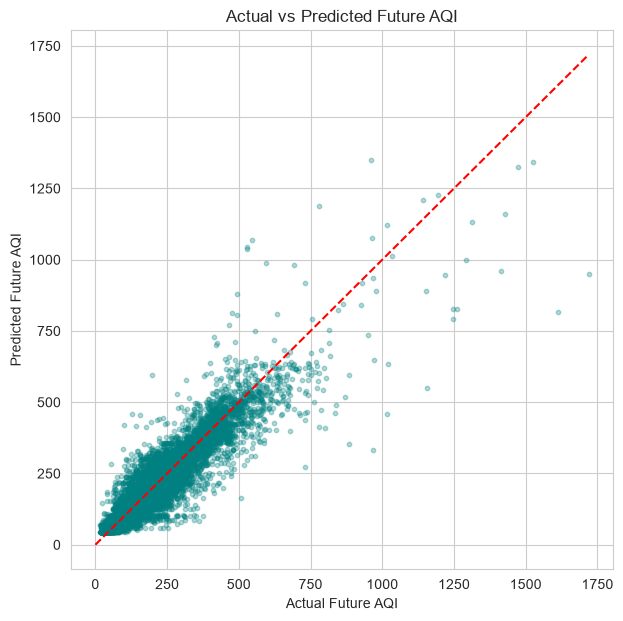

In [20]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.3, s=10, color='teal')
lims = [0, max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--')
plt.xlabel('Actual Future AQI')
plt.ylabel('Predicted Future AQI')
plt.title('Actual vs Predicted Future AQI')
plt.show()

### 10.3 Residual distribution
Residuals = Actual − Predicted. A distribution centred around 0 means the model is not biased.

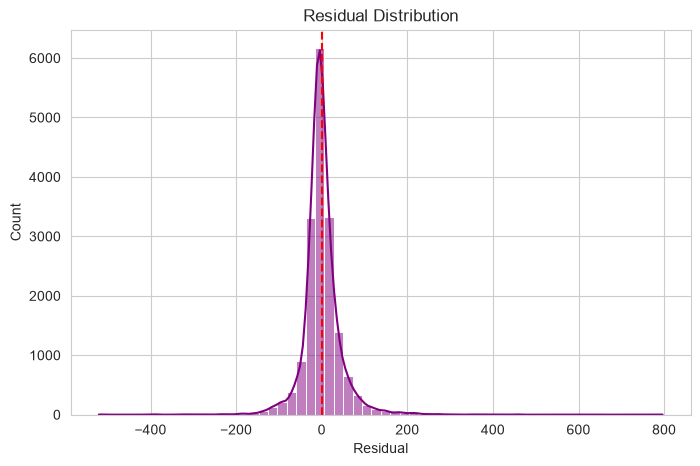

In [21]:
residuals = y_test - y_pred
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=60, kde=True, color='purple')
plt.axvline(0, color='red', linestyle='--')
plt.title('Residual Distribution')
plt.xlabel('Residual')
plt.show()

## Step 11: Feature Importance
Shows which pollutants contributed most to the Random Forest's predictions.

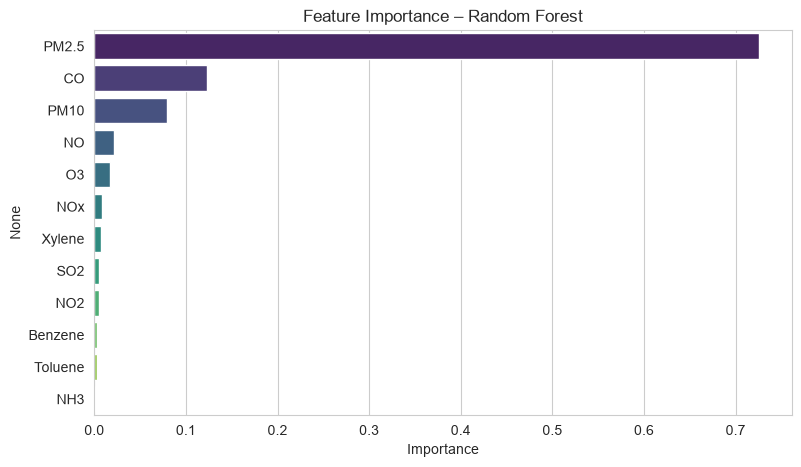

,Importance
PM2.5,0.725050
CO,0.123290
PM10,0.079658
NO,0.021846
O3,0.016684
NOx,0.008325
Xylene,0.007203
SO2,0.005625
NO2,0.004662
Benzene,0.003206


In [22]:
importance = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=importance.values, y=importance.index, palette='viridis')
plt.title('Feature Importance – Random Forest')
plt.xlabel('Importance')
plt.show()

importance.to_frame('Importance')

## Step 12: Saving the Model (Serialization)
The trained model and the imputer are saved with **joblib** so they can be reused without retraining.

In [23]:
joblib.dump(rf_model, 'random_forest_aqi_model.pkl')
joblib.dump(imputer, 'aqi_imputer.pkl')
print('Model saved to random_forest_aqi_model.pkl')
print('Imputer saved to aqi_imputer.pkl')

Model saved to random_forest_aqi_model.pkl
Imputer saved to aqi_imputer.pkl


## Step 13: Loading the Model & Predicting on New Data (Reusability)
A new day's pollutant readings are passed to the saved model to predict tomorrow's AQI. Missing readings (NaN) are filled by the saved imputer.

In [24]:
loaded_model = joblib.load('random_forest_aqi_model.pkl')
loaded_imputer = joblib.load('aqi_imputer.pkl')

new_data = pd.DataFrame([{
    'PM2.5': 81.4, 'PM10': 124.5, 'NO': 1.44, 'NO2': 20.5, 'NOx': 12.08, 'NH3': 10.72,
    'CO': 0.12, 'SO2': 15.24, 'O3': 127.09, 'Benzene': 0.2, 'Toluene': 6.5, 'Xylene': np.nan
}])

new_data_imp = loaded_imputer.transform(new_data[features])
predicted_aqi = loaded_model.predict(new_data_imp)[0]
print(f'Predicted AQI for the next day: {predicted_aqi:.2f}')

Predicted AQI for the next day: 187.19


### 13.1 Convert predicted AQI into AQI Bucket

In [25]:
def aqi_bucket(aqi):
    if aqi <= 50:
        return 'Good'
    elif aqi <= 100:
        return 'Satisfactory'
    elif aqi <= 200:
        return 'Moderate'
    elif aqi <= 300:
        return 'Poor'
    elif aqi <= 400:
        return 'Very Poor'
    else:
        return 'Severe'

print('Predicted AQI Category:', aqi_bucket(predicted_aqi))

Predicted AQI Category: Moderate


## Step 14: Conclusion
- The dataset was loaded, explored and cleaned; a new target **`Future_AQI`** (next day's AQI) was created per station.
- Missing pollutant values were handled using **median imputation**.
- A **Random Forest Regressor** (50 trees, max depth 10) was trained on 80% of the data and tested on 20%.
- The model was evaluated using **MSE, RMSE, MAE and R²**; the Actual-vs-Predicted plot and residuals show how well it fits.
- **Feature importance** shows that particulate matter (PM2.5 / PM10) and CO are the key drivers of next-day AQI.
- The trained model and imputer were saved and successfully reused to predict AQI for new readings.